In [1]:
# BLOCK 1 - Libraries and experiment settings
import io,json,time,hashlib,zipfile
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset,DataLoader
from scipy.optimize import minimize,Bounds,LinearConstraint,lsq_linear
from scipy.io import savemat,loadmat

NOTEBOOK_NAME='Koopman_MPC_New_design.ipynb'
NOTEBOOK_DIR=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/NOTEBOOK_NAME).is_file()),None)
if NOTEBOOK_DIR is None:
    notebook_matches=list(Path.cwd().glob(f'*/{NOTEBOOK_NAME}'))
    if len(notebook_matches)!=1:
        raise FileNotFoundError(f'Start Jupyter in the folder containing {NOTEBOOK_NAME}')
    NOTEBOOK_DIR=notebook_matches[0].parent
DATA_FILE=NOTEBOOK_DIR/'FlightTest_10132026.csv'
if not DATA_FILE.is_file():
    raise FileNotFoundError(f'{DATA_FILE.name} must be in the same folder as {NOTEBOOK_NAME}')
RUN_DIR=NOTEBOOK_DIR/'notebook_runs'/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
RUN_DIR.mkdir(parents=True,exist_ok=False)
SEED=123;np.random.seed(SEED);torch.manual_seed(SEED);torch.set_num_threads(2)
device=torch.device('cpu')
num_epochs=120;learning_rate=2e-5;batch_size=2048
TRAIN_PRINT_EVERY=1;MPC_PRINT_EVERY=10
PLOT_INPUT_RESPONSES=False
# Identification at the 10 Hz outer-command rate.
dt=.1;MPC_HORIZON=40;MPC_DT=.1;MPC_RADIUS=120.;MPC_ALTITUDE=60.;MPC_SPEED=18.
MPC_LAPS=2.;MPC_SIM_SECONDS=MPC_LAPS*2*np.pi*MPC_RADIUS/MPC_SPEED
MPC_SOLVES=int(np.ceil(MPC_SIM_SECONDS/MPC_DT))
# Joint roll/pitch/throttle MPC and a fitted nonlinear response surrogate.
print('Koopman identification and circular-path MPC')
print('Data file:',DATA_FILE)
print('Run directory:',RUN_DIR)


Koopman identification and circular-path MPC
Data file: C:\Users\ndini\desktop\OptiTraj\OptiTraj\altitude_revision_20261020\FlightTest_10132026.csv
Run directory: C:\Users\ndini\desktop\OptiTraj\OptiTraj\altitude_revision_20261020\notebook_runs\20261023_163614_294491


In [2]:
# BLOCK 2 - Flight data and chronological partitions
raw=DATA_FILE.read_bytes()
dataset_sha256=hashlib.sha256(raw).hexdigest();df=pd.read_csv(io.BytesIO(raw));del raw
required=['t','ATT_Roll','ATT_Pitch','ATT_Yaw','ATT_DesRoll','ATT_DesPitch',
          'IMU_GyrX','IMU_GyrY','IMU_GyrZ','CTUN_ThO','GPS_Alt','GPS_Lat','GPS_Lng','GPS_Spd','ARSP_Airspeed']
if not set(required)<=set(df):raise ValueError('Missing CSV columns: '+str(set(required)-set(df)))
df[required]=df[required].apply(pd.to_numeric,errors='coerce')
if not np.isfinite(df[required].to_numpy()).all():raise ValueError('Nonfinite input data')
raw_dt=float(np.median(np.diff(df.t)))
if not np.allclose(np.diff(df.t),raw_dt,rtol=.05,atol=1e-8):raise ValueError('Nonuniform source timestamps')
stride=int(round(dt/raw_dt))
if not np.isclose(stride*raw_dt,dt):raise ValueError('Source interval must divide identification dt')
datum=float(df.loc[df.t<=5,'GPS_Alt'].median())
# Causal GPS altitude difference.
lag=int(round(1/raw_dt))
df['climb']=(df.GPS_Alt-df.GPS_Alt.shift(lag))/(lag*raw_dt)
# Euler yaw rate from body gyros and attitude.
phi_log=np.deg2rad(df.ATT_Roll.to_numpy());theta_log=np.deg2rad(df.ATT_Pitch.to_numpy())
df['yaw_rate']=(df.IMU_GyrY*np.sin(phi_log)+df.IMU_GyrZ*np.cos(phi_log))/np.cos(theta_log)
lat=np.deg2rad(df.GPS_Lat.to_numpy());lon=np.unwrap(np.deg2rad(df.GPS_Lng.to_numpy()))
df['north']=6371000*(lat-lat[0]);df['east']=6371000*np.cos(lat[0])*(lon-lon[0])
df['vn']=(df.north-df.north.shift(lag))/(lag*raw_dt)
df['ve']=(df.east-df.east.shift(lag))/(lag*raw_dt)
flying=np.flatnonzero((df.t<=3420)&(df.ARSP_Airspeed>12)&(df.GPS_Spd>10)&(np.arange(len(df))>=lag))
runs=np.split(flying,np.flatnonzero(np.diff(flying)>1)+1);segment=max(runs,key=len)
df=df.iloc[segment[::stride]].copy().reset_index(drop=True)
if len(df)<2000:raise ValueError('Not enough continuous airborne data')
state_names=['phi','theta','p','q','r','h','airspeed','climb','yaw_rate']
state_units=['rad','rad','rad/s','rad/s','rad/s','m','m/s','m/s','rad/s']
input_names=['phi_command','theta_command','throttle']
input_units=['rad','rad','0_to_1']
PHI,THETA,P,Q,R,H_IDX,VA_IDX,CLIMB,YAW_RATE=range(9)
angles=np.deg2rad(df[['ATT_Roll','ATT_Pitch','ATT_Yaw']].to_numpy())
x=np.column_stack([angles[:,:2],df[['IMU_GyrX','IMU_GyrY','IMU_GyrZ']],df.GPS_Alt-datum,df.ARSP_Airspeed,df.climb,df.yaw_rate])
u=np.column_stack([np.deg2rad(df[['ATT_DesRoll','ATT_DesPitch']]),df.CTUN_ThO/100.])
yaw_measured=np.unwrap(angles[:,2])
yaw_difference=np.r_[x[0,YAW_RATE],np.diff(yaw_measured)/dt]
gyro_mid=np.r_[x[0,YAW_RATE],.5*(x[:-1,YAW_RATE]+x[1:,YAW_RATE])]
yaw_valid=np.abs(yaw_difference-gyro_mid)<.75
# Expand the heading-quality mask around inconsistent samples.
yaw_valid=np.convolve((~yaw_valid).astype(int),np.ones(5,dtype=int),mode='same')==0
bad_yaw_prefix=np.r_[0,np.cumsum(~yaw_valid)]
def valid_yaw_windows(ids,horizon):
    starts=np.asarray(ids,dtype=int)
    return (bad_yaw_prefix[starts+horizon+1]-bad_yaw_prefix[starts])==0
t=df.t.to_numpy();N=len(x);split=int(.7*N);val_end=int(.85*N);gap=50
parts={'train':(0,split),'validation':(split+gap,val_end),'test':(val_end+gap,N)}
X_mean=x[:split].mean(0);X_std=np.maximum(x[:split].std(0),1e-6)
U_mean=u[:split].mean(0);U_std=np.maximum(u[:split].std(0),1e-6)
X=torch.tensor((x-X_mean)/X_std,dtype=torch.float32)
U=torch.tensor((u-U_mean)/U_std,dtype=torch.float32)
# Estimate constant horizontal wind from the training partition.
va=x[:split,VA_IDX];vz=x[:split,CLIMB];yaw=angles[:split,2]
vh=np.sqrt(np.maximum(va**2-vz**2,0.))
WIND_NE=np.median(df[['vn','ve']].to_numpy()[:split]-vh[:,None]*np.c_[np.cos(yaw),np.sin(yaw)],axis=0)
audit={'dataset_sha256':dataset_sha256,'sample_time_s':dt,'altitude_datum_m':datum,
 'partitions':{k:{'start_s':float(t[a]),'end_s':float(t[b-1]),'rows':b-a} for k,(a,b) in parts.items()},
 'yaw_measurement':'Euler yaw rate from body gyros and attitude',
 'yaw_artifact_rows':int(np.sum(~yaw_valid)), 'yaw_artifact_threshold_radps':.75,
 'climb_measurement':'causal backward 1 s GPS-altitude derivative; includes filtering lag',
 'estimated_constant_wind_ne_mps':WIND_NE.tolist(),
 'limits':'Single-flight development dataset; upstream preprocessing unavailable; previously inspected holdout.'}
(RUN_DIR/'data_audit.json').write_text(json.dumps(audit,indent=2))
print(pd.DataFrame(audit['partitions']).T);print('States:',state_names,'Inputs:',input_names)
print('Estimated wind [N,E] m/s:',WIND_NE)
print(f'Log interval: {raw_dt:g} s; model interval: {dt:g} s ({stride} samples); plant substeps: {int(round(MPC_DT/.02))}.')


            start_s    end_s     rows
train        284.34  2464.74  21805.0
validation  2469.84  2932.04   4623.0
test        2937.14  3399.34   4623.0
States: ['phi', 'theta', 'p', 'q', 'r', 'h', 'airspeed', 'climb', 'yaw_rate'] Inputs: ['phi_command', 'theta_command', 'throttle']
Estimated wind [N,E] m/s: [4.88440218 1.56675565]
Log interval: 0.02 s; model interval: 0.1 s (5 samples); plant substeps: 5.


In [3]:
# BLOCK 3 - Pair and multi-step datasets
train_start,train_end=parts['train'];val_start,val_end=parts['validation'];test_start,test_end=parts['test']
train_loader=DataLoader(TensorDataset(X[:split-1],X[1:split],U[:split-1]),batch_size=batch_size,shuffle=True)
print('Training pairs:',split-1,'batches:',len(train_loader))


Training pairs: 21804 batches: 11


In [4]:
# BLOCK 4 - Lifted linear model with an explicit altitude integrator
num_state=9;num_input=3;feature_width=24;known_width=5;desired_koopman_dim=num_state+known_width+feature_width+1
# Normalized physical observables augment the learned lift.
def known_observables(physical):
    physical=np.asarray(physical);v=physical[...,VA_IDX];phi=physical[...,PHI];theta=physical[...,THETA]
    return np.stack([v*v,v*np.sin(theta),1/(v*np.cos(phi)),np.tan(phi)/v,v*np.cos(theta)],axis=-1)
known_train=known_observables(x[:split]);K_mean=known_train.mean(0);K_std=np.maximum(known_train.std(0),1e-6)
kmean_t=torch.tensor(K_mean,dtype=torch.float32);kstd_t=torch.tensor(K_std,dtype=torch.float32)
xmean_t=torch.tensor(X_mean,dtype=torch.float32);xstd_t=torch.tensor(X_std,dtype=torch.float32)
class Koopman(nn.Module):
    def __init__(self):
        super().__init__()
        self.W1=nn.Linear(num_state,feature_width,bias=False);self.W2=nn.Linear(feature_width,feature_width,bias=False)
        self.Araw=nn.Parameter(torch.eye(desired_koopman_dim));self.Braw=nn.Parameter(torch.zeros(desired_koopman_dim,3))
        mask=torch.ones(num_state);mask[H_IDX]=0;self.register_buffer('feature_mask',mask)
        amask=torch.ones(desired_koopman_dim,desired_koopman_dim);amask[:,H_IDX]=0;amask[-1,:]=0
        fixed=torch.zeros_like(amask);fixed[H_IDX,H_IDX]=1.;fixed[-1,-1]=1.
        # Unit height self-term and zero direct command feedthrough.
        bmask=torch.ones(desired_koopman_dim,3);bmask[H_IDX,:]=0;bmask[-1,:]=0
        self.register_buffer('amask',amask);self.register_buffer('fixed',fixed);self.register_buffer('bmask',bmask)
    def lift(self,x):
        f=torch.tanh(self.W2(torch.tanh(self.W1(x*self.feature_mask))))
        physical=x*xstd_t+xmean_t;v=physical[...,VA_IDX];phi=physical[...,PHI];theta=physical[...,THETA]
        known=torch.stack([v*v,v*torch.sin(theta),1/(v*torch.cos(phi)),torch.tan(phi)/v,v*torch.cos(theta)],dim=-1)
        known=(known-kmean_t)/kstd_t
        return torch.cat([x,known,f,torch.ones_like(x[...,:1])],-1)
    def matrices(self):return self.Araw*self.amask+self.fixed,self.Braw*self.bmask
    def forecast(self,x0,controls):
        A,B=self.matrices();z=self.lift(x0);pred=[]
        for j in range(controls.shape[1]):z=z@A.T+controls[:,j]@B.T;pred.append(z[:,:num_state])
        return torch.stack(pred,1)
model=Koopman().to(device)
# Ridge initialization of lifted increments.
with torch.no_grad():
    idx=torch.arange(0,split-1,2);z=model.lift(X[idx]).numpy().astype(float);zy=model.lift(X[idx+1]).numpy().astype(float)
    design=np.c_[z,U[idx].numpy()];design[:,H_IDX]=0
    coeff=np.linalg.solve(design.T@design/len(z)+1e-3*np.eye(design.shape[1]),design.T@(zy-z)/len(z))
    model.Araw.copy_(torch.tensor(np.eye(desired_koopman_dim)+coeff[:desired_koopman_dim].T,dtype=torch.float32))
    model.Braw.copy_(torch.tensor(coeff[desired_koopman_dim:].T,dtype=torch.float32))
print(model)


Koopman(
  (W1): Linear(in_features=9, out_features=24, bias=False)
  (W2): Linear(in_features=24, out_features=24, bias=False)
)


epoch 001/120: train=0.08469, val4s=1.24828, best epoch=1
epoch 002/120: train=0.08460, val4s=1.22202, best epoch=2
epoch 003/120: train=0.08484, val4s=1.19598, best epoch=3
epoch 004/120: train=0.08462, val4s=1.18236, best epoch=4
epoch 005/120: train=0.08474, val4s=1.17451, best epoch=5
epoch 006/120: train=0.08464, val4s=1.17734, best epoch=5
epoch 007/120: train=0.08464, val4s=1.16741, best epoch=7
epoch 008/120: train=0.08486, val4s=1.11668, best epoch=8
epoch 009/120: train=0.08481, val4s=1.08520, best epoch=9
epoch 010/120: train=0.08440, val4s=1.07473, best epoch=10
epoch 011/120: train=0.08455, val4s=1.06128, best epoch=11
epoch 012/120: train=0.08436, val4s=1.05422, best epoch=12
epoch 013/120: train=0.08429, val4s=1.04941, best epoch=13
epoch 014/120: train=0.08455, val4s=1.04138, best epoch=14
epoch 015/120: train=0.08471, val4s=1.04243, best epoch=14
epoch 016/120: train=0.08467, val4s=1.03707, best epoch=16
epoch 017/120: train=0.08451, val4s=1.01906, best epoch=17
epoch 

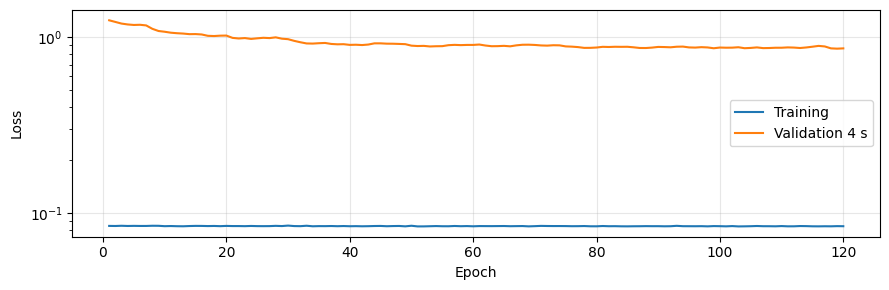

In [5]:
# BLOCK 5 - Training and checkpoint selection
optimizer=torch.optim.Adam(model.parameters(),lr=learning_rate);checkpoint=RUN_DIR/'best_model.pt'
weights=torch.tensor([2.,2.,.3,.3,.3,20.,2.,3.,4.]);history=[];best=float('inf');best_epoch=0
val_idx=torch.arange(val_start,val_end-41,40)
val_controls=torch.stack([U[val_idx+j] for j in range(40)],1)
val_truth=torch.stack([X[val_idx+j+1] for j in range(40)],1)
def loss_state(a,b):return torch.mean((a-b)**2*weights)
def yaw_increment_loss(prediction,ids):
    predicted_rate=prediction[...,YAW_RATE]*X_std[YAW_RATE]+X_mean[YAW_RATE]
    horizon=prediction.shape[1]
    rates=torch.cat([X[ids,YAW_RATE,None]*X_std[YAW_RATE]+X_mean[YAW_RATE],predicted_rate],dim=1)
    yaw_change=dt*torch.cumsum(.5*(rates[:,1:]+rates[:,:-1]),dim=1)
    target=torch.tensor(np.stack([yaw_measured[ids.numpy()+j+1]-yaw_measured[ids.numpy()] for j in range(horizon)],axis=1),dtype=torch.float32)
    valid=torch.tensor(valid_yaw_windows(ids.numpy(),horizon),dtype=torch.bool)
    if not bool(valid.any()):return prediction.sum()*0.
    return torch.mean(((yaw_change[valid]-target[valid])/.15)**2)
for epoch in range(num_epochs):
    model.train();total=0.
    for xb,yb,ub in train_loader:
        A_t,B_t=model.matrices();z=model.lift(xb);zn=z@A_t.T+ub@B_t.T
        loss=loss_state(zn[:,:num_state],yb)+.05*torch.mean((zn-model.lift(yb))**2)
        optimizer.zero_grad();loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),1.);optimizer.step();total+=float(loss.detach())
    horizon=10 if epoch<30 else (20 if epoch<70 else 40)
    for _ in range(3):
        ids=torch.randint(0,split-horizon-1,(64,));uc=torch.stack([U[ids+j] for j in range(horizon)],1)
        truth=torch.stack([X[ids+j+1] for j in range(horizon)],1);pred=model.forecast(X[ids],uc)
        loss=loss_state(pred,truth)+.5*yaw_increment_loss(pred,ids);optimizer.zero_grad();loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(),1.);optimizer.step()
    model.eval()
    with torch.no_grad():
        val_prediction=model.forecast(X[val_idx],val_controls)
        score=float(loss_state(val_prediction,val_truth)+.5*yaw_increment_loss(val_prediction,val_idx))
    if not np.isfinite(score):raise RuntimeError('Nonfinite training loss')
    if score<best:
        best=score;best_epoch=epoch+1;torch.save(model.state_dict(),checkpoint)
    history.append({'epoch':epoch+1,'horizon_steps':horizon,'training_loss':total/len(train_loader),'validation_4s_loss':score})
    if epoch%TRAIN_PRINT_EVERY==0 or epoch==num_epochs-1:print(f'epoch {epoch+1:03d}/{num_epochs}: train={total/len(train_loader):.5f}, val4s={score:.5f}, best epoch={best_epoch}',flush=True)
model.load_state_dict(torch.load(checkpoint,weights_only=True));model.eval()

# Multi-horizon least-squares calibration of the height row.
# Fit 0.1, 1, and 4 s increments with the remaining dynamics fixed.
with torch.no_grad():
    old_height_row=model.Araw[H_IDX].clone()
    fit_ids=np.arange(0,split-41,10)
    A_height,B_height=model.matrices();A_height=A_height.numpy().astype(float);B_height=B_height.numpy().astype(float)
    z_fit=model.lift(X[fit_ids]).numpy().astype(float);summed=np.zeros_like(z_fit);height_design=[];height_target=[]
    for j in range(40):
        summed+=z_fit;summed[:,H_IDX]=0.
        z_fit=z_fit@A_height.T+U[fit_ids+j].numpy()@B_height.T
        if j+1 in [1,10,40]:
            w=1/np.sqrt(j+1)
            height_design.append(w*summed.copy())
            height_target.append(w*(X[fit_ids+j+1,H_IDX].numpy()-X[fit_ids,H_IDX].numpy()))
    height_design=np.vstack(height_design);height_target=np.concatenate(height_target)
    prior=old_height_row.numpy().astype(float);prior[H_IDX]=0.
    ridge=.001
    fitted=np.linalg.solve(height_design.T@height_design/len(height_design)+ridge*np.eye(desired_koopman_dim),
        height_design.T@height_target/len(height_design)+ridge*prior)
    model.Araw[H_IDX].copy_(torch.tensor(fitted,dtype=torch.float32))
    calibrated_prediction=model.forecast(X[val_idx],val_controls)
    calibrated_score=float(loss_state(calibrated_prediction,val_truth)+.5*yaw_increment_loss(calibrated_prediction,val_idx))
    height_calibration_accepted=calibrated_score<best
    if height_calibration_accepted:
        best=calibrated_score;torch.save(model.state_dict(),checkpoint)
    else:model.Araw[H_IDX].copy_(old_height_row)
print('Height calibration accepted:',height_calibration_accepted,'validation score:',best)

pd.DataFrame(history).to_csv(RUN_DIR/'training_history.csv',index=False)
fig,ax=plt.subplots(figsize=(9,3));ax.semilogy(pd.DataFrame(history).epoch,pd.DataFrame(history).training_loss,label='Training')
ax.semilogy(pd.DataFrame(history).epoch,pd.DataFrame(history).validation_4s_loss,label='Validation 4 s')
ax.set(xlabel='Epoch',ylabel='Loss');ax.legend();ax.grid(alpha=.3);fig.tight_layout();fig.savefig(RUN_DIR/'training_iterations.png',dpi=150);plt.show()


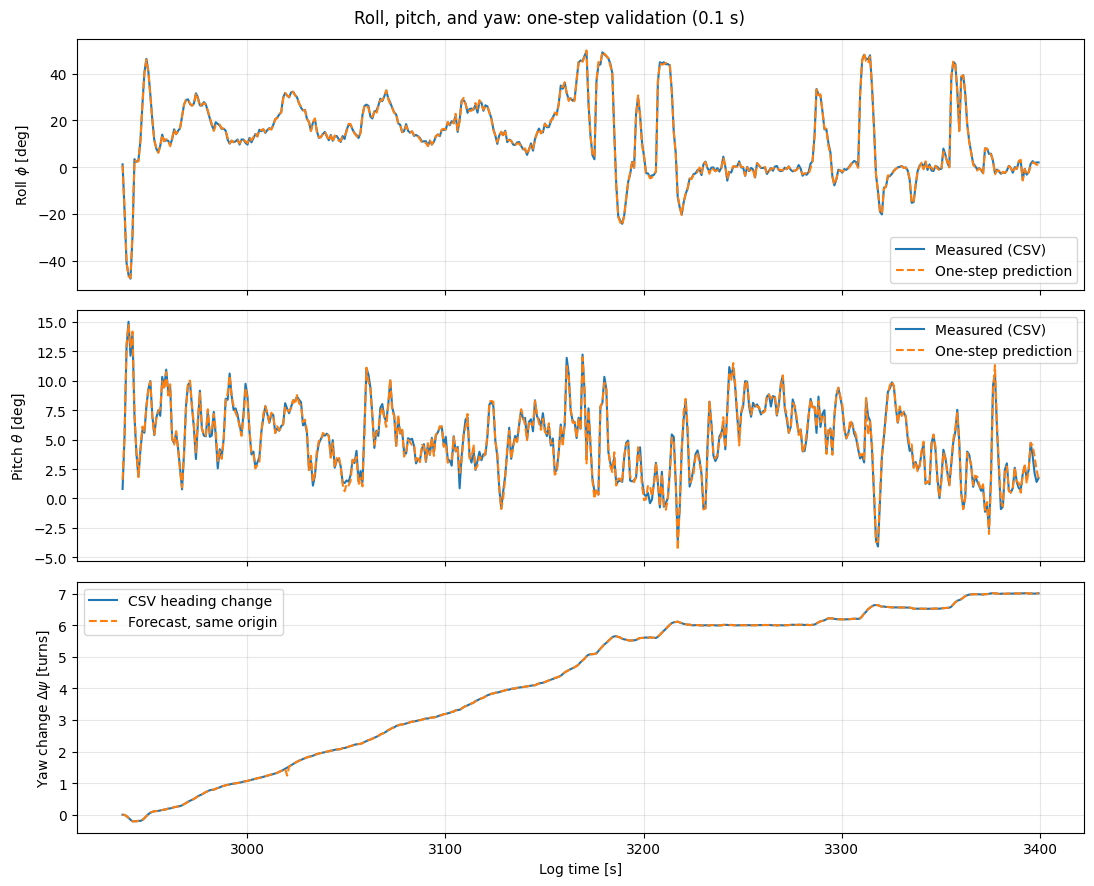

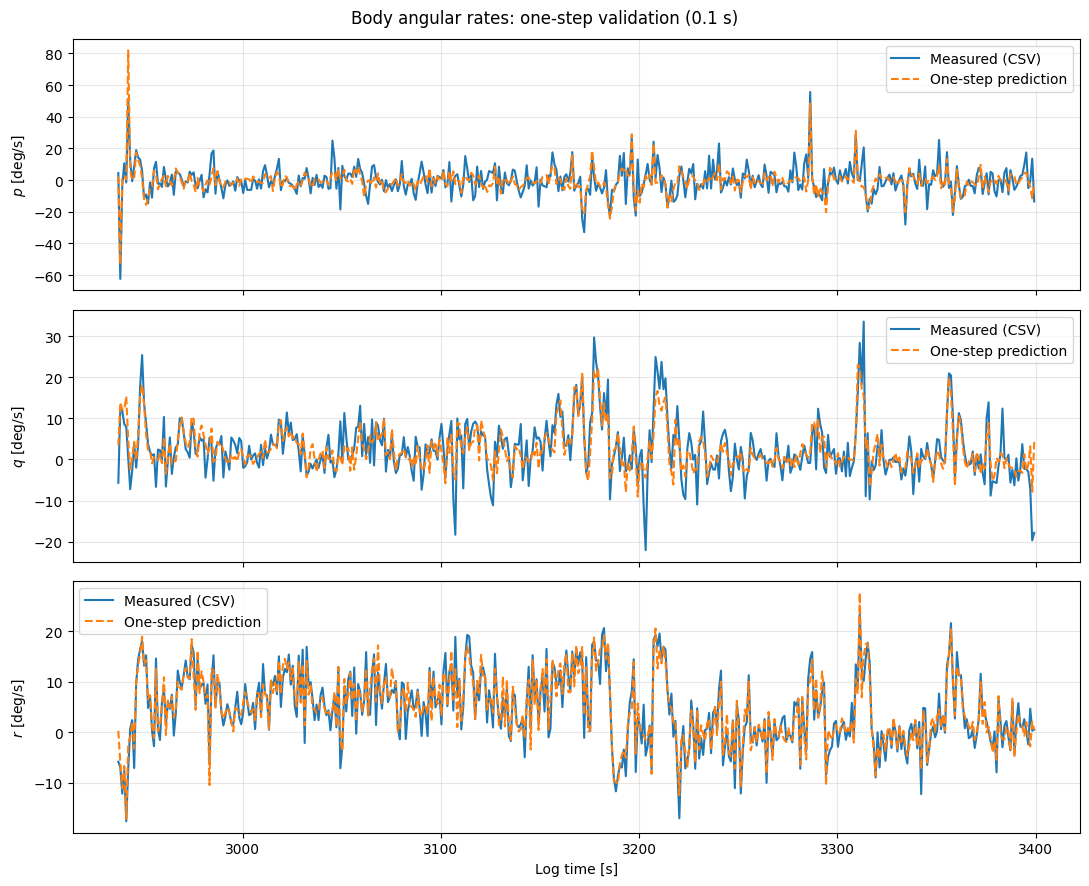

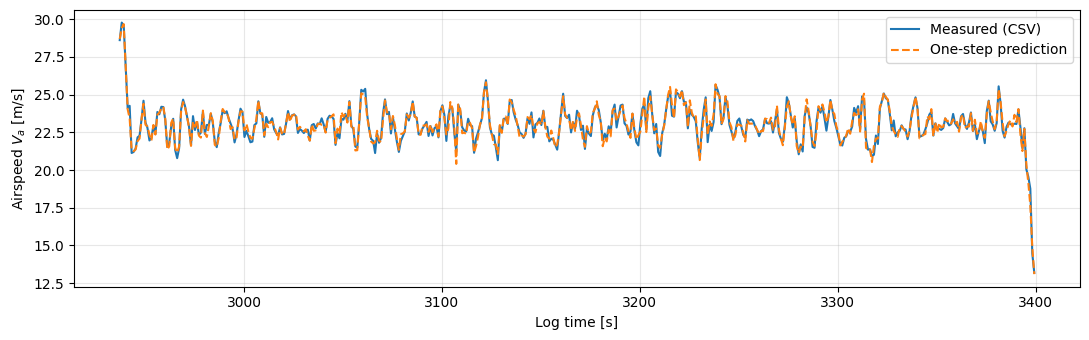

In [6]:
# BLOCK 6 - Model validation and nonlinear response surrogate
def heading_plot_data(times,continuous_heading_degrees,origin_degrees):
    turns=(np.asarray(continuous_heading_degrees,dtype=float)-origin_degrees)/360.
    return np.asarray(times,dtype=float),turns

metrics=[];yaw_metrics=[]
for horizon in [1,10,40]:
    ids=torch.arange(test_start,test_end-horizon-1,10)
    for policy in ['recorded_commands_conditional','held_current_commands']:
        uc=torch.stack([U[ids+j] for j in range(horizon)],1)
        if policy=='held_current_commands':uc[:]=uc[:,0:1].clone()
        with torch.no_grad():sequence=model.forecast(X[ids],uc).numpy()*X_std+X_mean
        pred=sequence[:,-1]
        initial_rate=x[ids.numpy(),YAW_RATE,None]
        yaw_rate_sequence=np.concatenate([initial_rate,sequence[...,YAW_RATE]],axis=1)
        yaw_forecast=yaw_measured[ids.numpy()]+dt*np.sum(.5*(yaw_rate_sequence[:,1:]+yaw_rate_sequence[:,:-1]),axis=1)
        yaw_truth=yaw_measured[ids.numpy()+horizon]
        yaw_error=np.arctan2(np.sin(yaw_forecast-yaw_truth),np.cos(yaw_forecast-yaw_truth))
        cv=yaw_measured[ids.numpy()]+horizon*dt*x[ids.numpy(),YAW_RATE]
        baseline_error=np.arctan2(np.sin(cv-yaw_truth),np.cos(cv-yaw_truth))
        valid_heading=valid_yaw_windows(ids.numpy(),horizon)
        yaw_metrics.append({'horizon_s':horizon*dt,'input_policy':policy,
            'valid_windows':int(valid_heading.sum()),'rejected_artifact_windows':int((~valid_heading).sum()),
            'yaw_rmse_deg':float(np.rad2deg(np.sqrt(np.mean(yaw_error[valid_heading]**2)))),
            'all_windows_yaw_rmse_deg':float(np.rad2deg(np.sqrt(np.mean(yaw_error**2)))),
            'constant_yaw_rate_rmse_deg':float(np.rad2deg(np.sqrt(np.mean(baseline_error[valid_heading]**2))))})
        truth=x[ids.numpy()+horizon];base=x[ids.numpy()]
        for j,name in enumerate(state_names):metrics.append({'state':name,'horizon_s':horizon*dt,'input_policy':policy,
            'rmse':float(np.sqrt(np.mean((pred[:,j]-truth[:,j])**2))),'persistence_rmse':float(np.sqrt(np.mean((base[:,j]-truth[:,j])**2)))})
    if horizon==1:
        plot_rows=ids.numpy()+1;plot_time=t[plot_rows]
        fig,axes=plt.subplots(3,1,figsize=(11,9),sharex=True)
        for ax,label,observed,forecast in [
            (axes[0],r'Roll $\phi$ [deg]',df.ATT_Roll.to_numpy()[plot_rows],np.rad2deg(pred[:,PHI])),
            (axes[1],r'Pitch $\theta$ [deg]',df.ATT_Pitch.to_numpy()[plot_rows],np.rad2deg(pred[:,THETA]))]:
            ax.plot(plot_time,observed,label='Measured (CSV)')
            ax.plot(plot_time,forecast,'--',label='One-step prediction');ax.set_ylabel(label)
        heading_origin=float(np.rad2deg(yaw_truth[0]))
        axes[2].plot(*heading_plot_data(plot_time,np.rad2deg(yaw_truth),heading_origin),label='CSV heading change')
        axes[2].plot(*heading_plot_data(plot_time,np.rad2deg(yaw_forecast),heading_origin),'--',label='Forecast, same origin')
        axes[2].set_ylabel(r'Yaw change $\Delta\psi$ [turns]')
        axes[-1].set_xlabel('Log time [s]')
        for ax in axes:ax.grid(alpha=.3);ax.legend()
        fig.suptitle('Roll, pitch, and yaw: one-step validation (0.1 s)');fig.tight_layout()
        fig.savefig(RUN_DIR/'attitude_one_step.png',dpi=160);plt.show()

        fig,axes=plt.subplots(3,1,figsize=(11,9),sharex=True)
        for ax,state_index,label in zip(axes,[P,Q,R],[r'$p$ [deg/s]',r'$q$ [deg/s]',r'$r$ [deg/s]']):
            ax.plot(plot_time,np.rad2deg(truth[:,state_index]),label='Measured (CSV)')
            ax.plot(plot_time,np.rad2deg(pred[:,state_index]),'--',label='One-step prediction')
            ax.set_ylabel(label);ax.grid(alpha=.3);ax.legend()
        axes[-1].set_xlabel('Log time [s]')
        fig.suptitle('Body angular rates: one-step validation (0.1 s)');fig.tight_layout()
        fig.savefig(RUN_DIR/'body_rates_one_step.png',dpi=160);plt.show()

        fig,ax=plt.subplots(figsize=(11,3.5))
        ax.plot(plot_time,truth[:,VA_IDX],label='Measured (CSV)')
        ax.plot(plot_time,pred[:,VA_IDX],'--',label='One-step prediction')
        ax.set(xlabel='Log time [s]',ylabel=r'Airspeed $V_a$ [m/s]')
        ax.grid(alpha=.3);ax.legend();fig.tight_layout()
        fig.savefig(RUN_DIR/'airspeed_one_step.png',dpi=160);plt.show()
pd.DataFrame(metrics).to_csv(RUN_DIR/'prediction_metrics.csv',index=False)
pd.DataFrame(yaw_metrics).to_csv(RUN_DIR/'yaw_forecast_metrics.csv',index=False)
# Four-second heading forecasts.
heading_rows=ids.numpy()+horizon;heading_time=t[heading_rows]
csv_heading_deg=df.ATT_Yaw.to_numpy()[heading_rows]
forecast_heading_deg=np.mod(np.rad2deg(yaw_forecast),360.)
heading_origin_deg=float(np.rad2deg(yaw_truth[0]))
display_csv_turns=(np.rad2deg(yaw_truth)-heading_origin_deg)/360.
display_prediction_turns=(np.rad2deg(yaw_forecast)-heading_origin_deg)/360.
heading_source_difference=(np.rad2deg(yaw_truth)-csv_heading_deg+180.)%360.-180.
np.testing.assert_allclose(heading_source_difference,0.,atol=1e-8)
pd.DataFrame({'time_s':heading_time,'source_csv_row_zero_based':segment[::stride][heading_rows],
    'csv_ATT_Yaw_deg':csv_heading_deg,'predicted_psi_deg':forecast_heading_deg,
    'display_csv_heading_change_turns':display_csv_turns,
    'display_predicted_heading_change_turns':display_prediction_turns,
    'display_reference_psi_deg':heading_origin_deg%360.,
    'circular_error_deg':np.rad2deg(yaw_error),'horizon_s':horizon*dt,
    'input_policy':policy,'valid_heading_window':valid_heading}).to_csv(RUN_DIR/'heading_forecast_trace.csv',index=False)
# Fit the nonlinear attitude and longitudinal response surrogate.
def fit_tracking(j):
    err=u[:split-1,j]-x[:split-1,j];target=np.diff(x[:split,j])/dt
    result=lsq_linear(np.c_[err,np.ones(len(err))],target,bounds=([.05,-.5],[10.,.5]))
    return result.x
roll_response=fit_tracking(PHI);pitch_response=fit_tracking(THETA)
# Parameter fitting uses the training partition.
fitlag=5
plant_idx=np.arange(fitlag,split-fitlag)
plant_target=(x[plant_idx+fitlag]-x[plant_idx])/(fitlag*dt)

# Point-mass energy balance and quasi-steady lift approximation.
fit_va=x[plant_idx,VA_IDX];fit_climb=x[plant_idx,CLIMB]
fit_phi=x[plant_idx,PHI];fit_theta=x[plant_idx,THETA]
alpha_observed=fit_theta-np.arcsin(np.clip(fit_climb/fit_va,-.99,.99))
alpha_features=np.c_[np.ones(len(plant_idx)),1/(fit_va**2*np.cos(fit_phi))]
alpha_coeff=lsq_linear(alpha_features,alpha_observed,bounds=([-.2,0.],[.2,100.])).x
climb_drive=fit_va*np.sin(fit_theta-alpha_features@alpha_coeff)-fit_climb
climb_response=float(lsq_linear(climb_drive[:,None],plant_target[:,CLIMB],bounds=(.05,5.)).x[0])
speed_features=np.c_[-fit_va**2,u[plant_idx,2]]
energy_target=plant_target[:,VA_IDX]+9.81*fit_climb/fit_va
speed_coeff=lsq_linear(speed_features,energy_target,bounds=(0.,np.inf)).x
plant_parameters={'roll_response':roll_response.tolist(),'pitch_response':pitch_response.tolist(),
    'drag_throttle_coeff':speed_coeff.tolist(),'alpha_coeff':alpha_coeff.tolist(),'climb_response':climb_response,'wind_ne_mps':WIND_NE.tolist(),
    'fit_partition':'train','shared_kinematics':'coordinated turn and velocity integration',
    'longitudinal_equations':'Va_dot=-drag*Va^2+thrust*T-g*climb/Va; climb_dot=k*(Va*sin(theta-alpha)-climb); alpha=a0+a1/(Va^2*cos(phi))',
    'structural_priors':'stable roll/pitch tracking; nonnegative drag/thrust/climb response; simple quasi-steady lift approximation',
    'status':'single-flight nonlinear response surrogate'}
(RUN_DIR/'surrogate_parameters.json').write_text(json.dumps(plant_parameters,indent=2));
def plant_step(state,commands,throttle):
    # State: north, east, yaw, and nine physical model states.
    out=np.asarray(state,dtype=float).copy();xp=out[3:].copy();old_phi=xp[PHI];old_theta=xp[THETA];old_yaw=out[2]
    controls=np.r_[commands,throttle]
    for _ in range(5):
        d=.02
        phidot=roll_response[0]*(commands[0]-xp[PHI])+roll_response[1]
        thetadot=pitch_response[0]*(commands[1]-xp[THETA])+pitch_response[1]
        alpha=alpha_coeff[0]+alpha_coeff[1]/(xp[VA_IDX]**2*np.cos(xp[PHI]))
        vdot=-speed_coeff[0]*xp[VA_IDX]**2+speed_coeff[1]*throttle-9.81*xp[CLIMB]/xp[VA_IDX]
        climbdot=climb_response*(xp[VA_IDX]*np.sin(xp[THETA]-alpha)-xp[CLIMB])
        previous=xp.copy();xp[PHI]+=d*phidot;xp[THETA]+=d*thetadot
        xp[VA_IDX]+=d*vdot;xp[CLIMB]+=d*climbdot;xp[H_IDX]+=d*.5*(previous[CLIMB]+xp[CLIMB])
        va=.5*(previous[VA_IDX]+xp[VA_IDX]);climb=.5*(previous[CLIMB]+xp[CLIMB])
        if not np.isfinite(xp).all() or va<=5 or abs(climb)>=va:raise RuntimeError('Nonlinear plant left flying model domain')
        yawdot=9.81*np.tan(.5*(previous[PHI]+xp[PHI]))/va
        course=out[2]+.5*d*yawdot;out[2]+=d*yawdot
        out[:2]+=d*(np.sqrt(va**2-climb**2)*np.array([np.cos(course),np.sin(course)])+WIND_NE)
    # Transform Euler derivatives to body rates.
    phi_mid=.5*(old_phi+xp[PHI]);theta_mid=.5*(old_theta+xp[THETA])
    phi_dot=(xp[PHI]-old_phi)/MPC_DT;theta_dot=(xp[THETA]-old_theta)/MPC_DT
    psi_dot=(out[2]-old_yaw)/MPC_DT
    xp[P]=phi_dot-psi_dot*np.sin(theta_mid)
    xp[Q]=theta_dot*np.cos(phi_mid)+psi_dot*np.sin(phi_mid)*np.cos(theta_mid)
    xp[R]=-theta_dot*np.sin(phi_mid)+psi_dot*np.cos(phi_mid)*np.cos(theta_mid)
    xp[YAW_RATE]=psi_dot
    out[3:]=xp
    return out
# One-step surrogate validation.
test_ids=np.arange(test_start,test_end-1,10);surrogate_errors=[]
for i in test_ids:
    s=np.r_[df.loc[i,['north','east']].to_numpy(dtype=float),angles[i,2],x[i]]
    simulated=plant_step(s,u[i,:2],u[i,2])[3:]
    surrogate_errors.append(simulated-x[i+1])
plant_metrics={'horizon_s':MPC_DT,'state_rmse':dict(zip(state_names,np.sqrt(np.mean(np.asarray(surrogate_errors)**2,axis=0)).tolist()))}
(RUN_DIR/'surrogate_holdout_metrics.json').write_text(json.dumps(plant_metrics,indent=2));


In [7]:
# BLOCK 7 - Model export and command responses
with torch.no_grad():
    A_t,B_t=model.matrices();A=A_t.numpy();B=B_t.numpy()
    W1=model.W1.weight.numpy()*model.feature_mask.numpy()[None,:];W2=model.W2.weight.numpy()
C=np.eye(desired_koopman_dim)[:num_state];D=np.zeros((num_state,num_input))
metadata={'format_version':6,'model_family':'october_hybrid_yaw_altitude_v5','state_names':state_names,'state_units':state_units,
    'input_names':input_names,'input_units':input_units,'sample_time':dt,'koopman_dimension':desired_koopman_dim,
    'lift':'[normalized x;normalized known observables;tanh(W2*tanh(W1*normalized x));1]',
    'known_observables':['Va^2','Va*sin(theta)','1/(Va*cos(phi))','tan(phi)/Va','Va*cos(theta)'],
    'learned_feature_width':feature_width,'known_feature_width':known_width,'transition':'z_next=A*z+B*u; initialize z from the measured state',
    'altitude_integrator':'h_next=h+learned_increment; height-translation invariant dynamics; delayed GPS-difference climb state','best_epoch':best_epoch,'epochs_run':num_epochs,
    'validation_4s_loss':best,'training_height_calibration_accepted':height_calibration_accepted,
    'height_input_structure':'B_h=0; commands influence learned height increments through aircraft states','dataset_sha256':dataset_sha256,'altitude_datum_m':datum,'data_audit':audit,
    'position_prediction':'velocity kinematics with trapezoidal integration of learned yaw rate',
    'plant_validation':'nonlinear response surrogate fitted to the training partition; shared kinematics','sitl_tested':False,'flight_approved':False}
payload={'A':A,'B':B,'C':C,'D':D,'W1':W1,'W2':W2,'K_mean':K_mean,'K_std':K_std,'X_mean':X_mean,'X_std':X_std,'U_mean':U_mean,'U_std':U_std,
    'metadata_json':json.dumps(metadata)}
np.savez_compressed(RUN_DIR/'model.npz',**{k:v for k,v in payload.items() if k!='metadata_json'},metadata=json.dumps(metadata))
savemat(RUN_DIR/'Koopman_altitude_weights.mat',payload,do_compression=True)
torch.save({'state_dict':model.state_dict(),'metadata':metadata},RUN_DIR/'Koopman_altitude_weights.pt')
(RUN_DIR/'metadata.json').write_text(json.dumps(metadata,indent=2))
def lift_numpy(physical):
    normalized=(np.asarray(physical)-X_mean)/X_std
    return np.concatenate([normalized,(known_observables(physical)-K_mean)/K_std,np.tanh(np.tanh(normalized@W1.T)@W2.T),np.ones_like(normalized[...,:1])],axis=-1)
def decode_numpy(z):return (np.asarray(z)@C.T)*X_std+X_mean
# Check NumPy and PyTorch forecast agreement.
z=lift_numpy(x[test_start]);uc=u[test_start:test_start+40];numpy_states=[]
for control in uc:z=z@A.T+((control-U_mean)/U_std)@B.T;numpy_states.append(decode_numpy(z))
with torch.no_grad():torch_states=model.forecast(X[test_start:test_start+1],U[test_start:test_start+40][None,:])[0].numpy()*X_std+X_mean
np.testing.assert_allclose(numpy_states,torch_states,atol=1e-3,rtol=2e-4)
verification={'numpy_torch_4s_max_error':float(np.max(np.abs(np.asarray(numpy_states)-torch_states)))}
(RUN_DIR/'verification.json').write_text(json.dumps(verification,indent=2));print('Export verification:',verification)

# Pitch and throttle step responses.
responses=[]
for input_index,increment,label in [(1,np.deg2rad(1.),'pitch_plus_1deg'),(2,.05,'throttle_plus_5pct')]:
    dz=np.zeros(desired_koopman_dim);du=np.zeros(num_input);du[input_index]=increment/U_std[input_index]
    for j in range(40):
        dz=dz@A.T+du@B.T;response=(dz@C.T)*X_std
        responses.append({'input_change':label,'time_s':(j+1)*dt,'delta_altitude_m':response[H_IDX],
            'delta_airspeed_mps':response[VA_IDX],'delta_climb_mps':response[CLIMB]})
response_table=pd.DataFrame(responses);response_table.to_csv(RUN_DIR/'pitch_throttle_identified_responses.csv',index=False)
if PLOT_INPUT_RESPONSES:
    fig,axes=plt.subplots(2,1,sharex=True,figsize=(9,6))
    response_labels={'pitch_plus_1deg':'Pitch command +1 deg','throttle_plus_5pct':'Throttle +5 percentage points'}
    for label,group in response_table.groupby('input_change'):
        axes[0].plot(group.time_s,group.delta_altitude_m,label=response_labels[label])
        axes[1].plot(group.time_s,group.delta_airspeed_mps,label=response_labels[label])
    axes[0].set_ylabel('Predicted altitude change [m]');axes[1].set_ylabel('Predicted airspeed change [m/s]');axes[1].set_xlabel('Time [s]')
    for ax in axes:ax.legend();ax.grid(alpha=.3)
    fig.suptitle('Koopman input-step responses');fig.tight_layout()
    fig.savefig(RUN_DIR/'pitch_throttle_identified_responses.png',dpi=160);plt.show()
handoff="""Koopman model: october_hybrid_yaw_altitude_v5
State: [phi,theta,p,q,r,h,airspeed,filtered_climb,yaw_rate], SI units.
Commands: [roll rad,pitch rad,throttle 0..1]. Sample time: 0.1 s.
Matrices: A39x39, B39x3, C9x39, D9x3; encoder and normalization included.
Prediction: initialize the lift from the measured state, then propagate z_next=A*z+B*u.
Heading integrates learned yaw rate; position follows velocity kinematics.
MPC jointly supplies roll, pitch, and throttle commands.
Throttle-to-altitude sensitivity is weak. Model sensitivities are observational
estimates; causal gains require controlled excitation.
Validation: flight-log forecasts and circular-path simulation with a nonlinear
response surrogate fitted to the training partition. SITL validation: pending.
State ordering, units, and provenance are recorded in metadata.json.
"""
(RUN_DIR/'HANDOFF_FOR_JUSTIN.txt').write_text(handoff)
with zipfile.ZipFile(RUN_DIR/'justin_altitude_weights.zip','w',zipfile.ZIP_DEFLATED) as archive:
    for name in ['model.npz','Koopman_altitude_weights.mat','Koopman_altitude_weights.pt','metadata.json',
                 'HANDOFF_FOR_JUSTIN.txt','prediction_metrics.csv','yaw_forecast_metrics.csv','pitch_throttle_identified_responses.csv']:
        archive.write(RUN_DIR/name,arcname=name)
print('Weight archive:',RUN_DIR/'justin_altitude_weights.zip')


Export verification: {'numpy_torch_4s_max_error': 7.884719863682221e-06}
Weight archive: C:\Users\ndini\desktop\OptiTraj\OptiTraj\altitude_revision_20261020\notebook_runs\20261023_163614_294491\justin_altitude_weights.zip


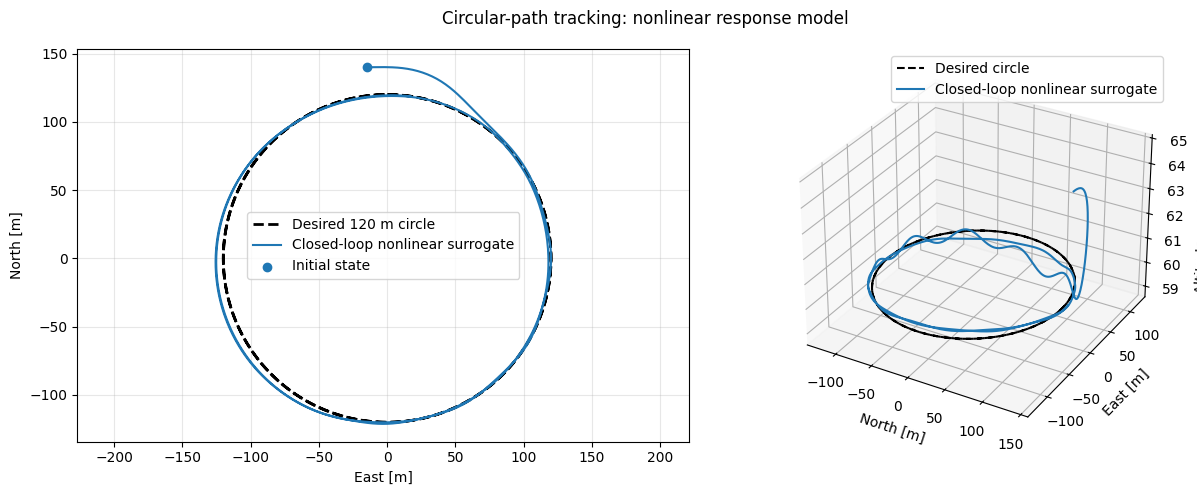

In [8]:
# BLOCK 8 - Circular-path MPC simulation
# Plant state: [north,east,yaw,phi,theta,p,q,r,h,airspeed,climb,yaw_rate].
# MPC prediction: [north,east,yaw,lifted aircraft state].
# Heading prediction integrates learned yaw rate.
POSITION_ERROR_SCALES=np.array([3.,3.,.5]);COMMAND_CHANGE_WEIGHT=.3;PITCH_CHANGE_WEIGHT=.3
CLIMB_ERROR_SCALE=1.;CLIMB_WEIGHT=10.;TERMINAL_CLIMB_WEIGHT=50.
VERTICAL_ERROR_GAIN=.1;VERTICAL_DYNAMICS_WEIGHT=200.
ALTITUDE_INTEGRAL_WEIGHT=3.;ALTITUDE_INTEGRAL_LIMIT=30.
MATCH_CLIMB_SENSOR=True
VELOCITY_WEIGHT=1.;SQP_ITERATIONS=2
mpc_horizon=MPC_HORIZON;nz=len(A);nh=nz+3
# Interpolated command knots over the full prediction horizon.
# Enforce command and slew limits at each prediction stage.
knot_indices=np.unique(np.r_[np.arange(0,mpc_horizon,6),mpc_horizon-1])
n_knots=len(knot_indices);nd=3*n_knots
interpolation=np.column_stack([np.interp(np.arange(mpc_horizon),knot_indices,np.eye(n_knots)[j]) for j in range(n_knots)])
command_map=np.kron(interpolation,np.eye(3));full_nd=3*mpc_horizon
# Augmented height/drift observer.
model_bias=np.zeros(nz);HEIGHT_UPDATE=.7;HEIGHT_DRIFT_UPDATE=.2
limits=np.r_[np.deg2rad([30.,12.]),1.];lower=np.r_[-limits[:2],0.];slew=np.r_[np.deg2rad([30.,20.]),.5]*MPC_DT

def ground_speed(physical,yaw):
    va=physical[...,VA_IDX];climb=physical[...,CLIMB]
    if np.any(va<=5) or np.any(np.abs(climb)>=va):raise ValueError('State outside flying velocity domain')
    horizontal=np.sqrt(va**2-climb**2)
    velocity=horizontal[...,None]*np.stack([np.cos(yaw),np.sin(yaw)],axis=-1)+WIND_NE
    return np.linalg.norm(velocity,axis=-1)

def hybrid_prediction(state,commands):
    # Hybrid state transition.
    pos=state[...,:2];yaw=state[...,2];z=state[...,3:]
    before=decode_numpy(z);control=commands
    zn=z@A.T+((control-U_mean)/U_std)@B.T
    zn+=model_bias
    after=decode_numpy(zn)
    velocity=.5*(before[...,VA_IDX]+after[...,VA_IDX]);climb=.5*(before[...,CLIMB]+after[...,CLIMB])
    if not np.isfinite(after).all() or np.any(velocity<=5) or np.any(np.abs(climb)>=velocity):
        raise ValueError('Koopman horizon left the flying prediction domain')
    bank=.5*(before[...,PHI]+after[...,PHI])
    if np.any(np.abs(bank)>=np.deg2rad(75)):raise ValueError('Predicted bank outside kinematic domain')
    yawrate=.5*(before[...,YAW_RATE]+after[...,YAW_RATE]);yaw_next=yaw+MPC_DT*yawrate
    course=.5*(yaw+yaw_next);horizontal=np.sqrt(velocity**2-climb**2)
    pos_next=pos+MPC_DT*(horizontal[...,None]*np.stack([np.cos(course),np.sin(course)],axis=-1)+WIND_NE)
    return np.concatenate([pos_next,yaw_next[...,None],zn],axis=-1)

def observe_plant(state,history):
    physical=state[3:].copy()
    if MATCH_CLIMB_SENSOR:
        # Match the causal GPS-difference state used for identification.
        lag_steps=int(round(1./MPC_DT));past=max(0,len(history)-lag_steps)
        duration=(len(history)-past)*MPC_DT
        if duration>0:physical[CLIMB]=(state[3+H_IDX]-history[past][3+H_IDX])/duration
    return physical

def rollout(initial,commands):
    result=[initial]
    for cmd in commands:result.append(hybrid_prediction(result[-1],cmd))
    return np.asarray(result)

def jacobians(state,command):
    before=decode_numpy(state[3:]);after=decode_numpy(hybrid_prediction(state,command)[3:])
    bu=B/U_std[None,:]
    velocity=.5*(before[VA_IDX]+after[VA_IDX]);climb=.5*(before[CLIMB]+after[CLIMB])
    horizontal=np.sqrt(velocity**2-climb**2)
    yawrate=.5*(before[YAW_RATE]+after[YAW_RATE]);course=state[2]+.5*MPC_DT*yawrate
    direction=np.array([np.cos(course),np.sin(course)]);perpendicular=np.array([-direction[1],direction[0]])
    v_z=.5*X_std[VA_IDX]*(C[VA_IDX]+C[VA_IDX]@A);v_u=.5*X_std[VA_IDX]*(C[VA_IDX]@bu)
    c_z=.5*X_std[CLIMB]*(C[CLIMB]+C[CLIMB]@A);c_u=.5*X_std[CLIMB]*(C[CLIMB]@bu)
    h_z=(velocity*v_z-climb*c_z)/horizontal;h_u=(velocity*v_u-climb*c_u)/horizontal
    yaw_z=.5*MPC_DT*X_std[YAW_RATE]*(C[YAW_RATE]+C[YAW_RATE]@A)
    yaw_u=.5*MPC_DT*X_std[YAW_RATE]*(C[YAW_RATE]@bu)
    Fx=np.zeros((nh,nh));Fu=np.zeros((nh,3))
    Fx[:2,:2]=np.eye(2);Fx[2,2]=1.;Fx[3:,3:]=A;Fu[3:]=bu
    Fx[:2,2]=MPC_DT*horizontal*perpendicular
    Fx[:2,3:]=MPC_DT*(direction[:,None]*h_z[None,:]+.5*horizontal*perpendicular[:,None]*yaw_z[None,:])
    Fu[:2]=MPC_DT*(direction[:,None]*h_u[None,:]+.5*horizontal*perpendicular[:,None]*yaw_u[None,:])
    Fx[2,3:]=yaw_z;Fu[2]=yaw_u
    return Fx,Fu

center=np.array([0.,0.]);phase0=0.
def desired_path(times):
    phase=phase0+MPC_SPEED/MPC_RADIUS*np.asarray(times)
    return np.stack([center[0]+MPC_RADIUS*np.cos(phase),center[1]+MPC_RADIUS*np.sin(phase),np.full_like(phase,MPC_ALTITUDE)],axis=-1)
position_map=np.zeros((3,nh));position_map[0,0]=position_map[1,1]=1;position_map[2,3+H_IDX]=X_std[H_IDX]
position_offset=np.array([0.,0.,X_mean[H_IDX]])
delta=np.eye(full_nd)
for j in range(3,full_nd):delta[j,j-3]=-1
input_scale=np.tile(limits,mpc_horizon);rate_bounds=np.tile(slew,mpc_horizon)
knot_scale=np.tile(limits,n_knots)
change_weights=np.tile([COMMAND_CHANGE_WEIGHT,PITCH_CHANGE_WEIGHT,.3],mpc_horizon)
rate_map=(delta@command_map)*knot_scale[None,:]
unique_rate_map,rate_groups=np.unique(rate_map,axis=0,return_inverse=True)
np.testing.assert_array_equal(unique_rate_map[rate_groups],rate_map)

def solve_mpc_qp(state,warm,last,targets):
    started=time.perf_counter()
    knots=warm[knot_indices].ravel();flat=command_map@knots;warm=flat.reshape(-1,3)
    nominal=rollout(state,warm)
    integral_sensitivity=np.zeros(nd);predicted_height_integral=altitude_integral
    sensitivity=np.zeros((nh,nd));design=[];residual=[]
    for k in range(mpc_horizon):
        previous_sensitivity=sensitivity.copy()
        Fx,Fu=jacobians(nominal[k],warm[k]);sensitivity=Fx@sensitivity;sensitivity+=Fu@command_map[3*k:3*k+3]
        weight=np.sqrt(8. if k==mpc_horizon-1 else 1/mpc_horizon)
        design.append(weight*(position_map@sensitivity)/POSITION_ERROR_SCALES[:,None])
        residual.append(weight*(position_map@nominal[k+1]+position_offset-targets[k])/POSITION_ERROR_SCALES)
        physical=decode_numpy(nominal[k+1,3:])
        if VELOCITY_WEIGHT>0:
            desired_velocity=MPC_SPEED/MPC_RADIUS*np.array([-(targets[k,1]-center[1]),targets[k,0]-center[0]])
            yaw=nominal[k+1,2];direction=np.array([np.cos(yaw),np.sin(yaw)])
            horizontal=np.sqrt(physical[VA_IDX]**2-physical[CLIMB]**2)
            predicted_velocity=horizontal*direction+WIND_NE
            velocity_jacobian=np.zeros((2,nh))
            velocity_jacobian[:,2]=horizontal*np.array([-np.sin(yaw),np.cos(yaw)])
            velocity_jacobian[:,3+VA_IDX]=physical[VA_IDX]/horizontal*X_std[VA_IDX]*direction
            velocity_jacobian[:,3+CLIMB]=-physical[CLIMB]/horizontal*X_std[CLIMB]*direction
            vw=np.sqrt(VELOCITY_WEIGHT*(1. if k==mpc_horizon-1 else 1/mpc_horizon))
            design.append(vw*(velocity_jacobian@sensitivity))
            residual.append(vw*(predicted_velocity-desired_velocity))
        predicted_height_integral+=MPC_DT*(physical[H_IDX]-targets[k,2])
        integral_sensitivity+=MPC_DT*(position_map@sensitivity)[2]
        if k==mpc_horizon-1:
            integral_weight=np.sqrt(ALTITUDE_INTEGRAL_WEIGHT)
            design.append((integral_weight*integral_sensitivity)[None,:])
            residual.append(np.array([integral_weight*predicted_height_integral]))
        # Vertical damping from predicted height increments.
        previous_physical=decode_numpy(nominal[k,3:])
        predicted_vertical_speed=(physical[H_IDX]-previous_physical[H_IDX])/MPC_DT
        vertical_speed_sensitivity=X_std[H_IDX]*(sensitivity[3+H_IDX]-previous_sensitivity[3+H_IDX])/MPC_DT
        climb_weight=np.sqrt(TERMINAL_CLIMB_WEIGHT if k==mpc_horizon-1 else CLIMB_WEIGHT/mpc_horizon)
        design.append((climb_weight*vertical_speed_sensitivity/CLIMB_ERROR_SCALE)[None,:])
        residual.append(np.array([climb_weight*predicted_vertical_speed/CLIMB_ERROR_SCALE]))
        if VERTICAL_DYNAMICS_WEIGHT>0:
            damping_weight=np.sqrt(VERTICAL_DYNAMICS_WEIGHT*(1. if k==mpc_horizon-1 else 1/mpc_horizon))
            design.append((damping_weight*(vertical_speed_sensitivity+VERTICAL_ERROR_GAIN*(position_map@sensitivity)[2]))[None,:])
            residual.append(np.array([damping_weight*(predicted_vertical_speed+VERTICAL_ERROR_GAIN*(physical[H_IDX]-targets[k,2]))]))
        for j,w,scale in [(P,.02,.5),(Q,.08,.3)]:
            design.append((w*X_std[j]*sensitivity[3+j]/scale)[None,:]);residual.append(np.array([w*physical[j]/scale]))
        for j,lo,hi,scale in [(PHI,-limits[0],limits[0],.15),(THETA,-limits[1],limits[1],.1),(H_IDX,20.,120.,10.)]:
            value=physical[j]
            if value<lo or value>hi:
                design.append((2*X_std[j]*sensitivity[3+j]/scale)[None,:])
                residual.append(np.array([2*(value-np.clip(value,lo,hi))/scale]))
    movement=delta@flat-np.r_[last,np.zeros(full_nd-3)]
    design.extend([.015*command_map/input_scale[:,None],change_weights[:,None]*(delta@command_map)/input_scale[:,None]])
    residual.extend([.015*flat/input_scale,change_weights*movement/input_scale])
    J=np.vstack(design);r=np.concatenate(residual);Hq=2*(J.T@J+1e-6*np.eye(nd));g=2*J.T@r
    Hs=knot_scale[:,None]*Hq*knot_scale[None,:];gs=knot_scale*g
    scale=max(1.,np.linalg.norm(Hs,ord=np.inf),np.linalg.norm(gs,ord=np.inf));Hs/=scale;gs/=scale
    rate_lower=np.full(len(unique_rate_map),-np.inf);rate_upper=np.full(len(unique_rate_map),np.inf)
    np.maximum.at(rate_lower,rate_groups,-rate_bounds-movement)
    np.minimum.at(rate_upper,rate_groups,rate_bounds-movement)
    qp_constraints=[LinearConstraint(unique_rate_map,rate_lower,rate_upper)]
    solution=minimize(lambda v:.5*v@Hs@v+gs@v,np.zeros(nd),jac=lambda v:Hs@v+gs,
        method='SLSQP',bounds=Bounds((np.tile(lower,n_knots)-knots)/knot_scale,(knot_scale-knots)/knot_scale),
        constraints=qp_constraints,
        options={'maxiter':300,'ftol':1e-7})
    if not solution.success:raise RuntimeError('MPC optimization failed: '+str(solution.message))
    commands=(command_map@(knots+knot_scale*solution.x)).reshape(-1,3)
    if (np.any(commands<lower-1e-6) or np.any(commands>limits+1e-6)) or np.any(np.abs(np.diff(np.vstack([last,commands]),axis=0))>slew+1e-6):
        raise RuntimeError('Command magnitude or slew constraint violation')
    predicted=rollout(state,commands);elapsed=time.perf_counter()-started
    return commands[0],np.vstack([commands[1:],commands[-1]]),predicted,elapsed,int(solution.nit)

def koopman_mpc_u0(state,warm,last,targets):
    started=time.perf_counter();total=0
    for refinement in range(SQP_ITERATIONS):
        command,shifted,predicted,elapsed,iterations=solve_mpc_qp(state,warm,last,targets)
        total+=iterations;warm=np.vstack([command,shifted[:-1]])
    return command,shifted,predicted,time.perf_counter()-started,total

# Start off the circle and altitude with a heading error and zero bank.
initial_physical=X_mean.copy();initial_physical[[PHI,P,Q,R,YAW_RATE]]=0.
initial_physical[H_IDX]=MPC_ALTITUDE+5.;initial_physical[VA_IDX]=MPC_SPEED;initial_physical[CLIMB]=0.
initial_yaw=np.pi/2+np.deg2rad(15)
plant_state=np.r_[MPC_RADIUS+20.,-15.,initial_yaw,initial_physical]
last_command=np.array([0.,np.clip(initial_physical[THETA],-limits[1],limits[1]),0.])
warm=np.tile(last_command,(mpc_horizon,1));altitude_integral=0.;height_estimate=None;records=[];failure=None
states=[plant_state.copy()];times=[0.]
for k in range(MPC_SOLVES):
    now=k*MPC_DT
    # Simulated measurement update.
    physical=observe_plant(plant_state,states[:-1]);measured_pose=plant_state[:3].copy()
    if height_estimate is None:height_estimate=float(physical[H_IDX])
    physical[H_IDX]=height_estimate
    state=np.r_[measured_pose,lift_numpy(physical)]
    targets=desired_path(now+MPC_DT*np.arange(1,mpc_horizon+1))
    try:
        control,warm,predicted,elapsed,iterations=koopman_mpc_u0(state,warm,last_command,targets)
        command=control[:2];throttle=float(control[2])
        old_z=lift_numpy(physical)
        unbiased=old_z@A.T+((np.r_[command,throttle]-U_mean)/U_std)@B.T
        plant_state=plant_step(plant_state,command,throttle)
        if plant_state[3+H_IDX]<0.:raise RuntimeError('Simulated altitude crossed the configured zero-datum floor')
        measurement=observe_plant(plant_state,states);raw_height=float(measurement[H_IDX])
        predicted_height=(unbiased[H_IDX]+model_bias[H_IDX])*X_std[H_IDX]+X_mean[H_IDX]
        height_innovation=raw_height-predicted_height
        height_estimate=float(predicted_height+HEIGHT_UPDATE*height_innovation)
        model_bias[H_IDX]+=HEIGHT_DRIFT_UPDATE*height_innovation/X_std[H_IDX]
        measurement[H_IDX]=height_estimate
    except (RuntimeError,ValueError) as exc:
        failure={'step':k,'time_s':now,'reason':str(exc)};print('Simulation stopped:',failure,flush=True);break
    last_command=control.copy();after=plant_state[3:]
    # Conditional integration at the pitch-command limits.
    height_error=measurement[H_IDX]-MPC_ALTITUDE
    if not ((command[1]<=-limits[1]+1e-6 and height_error>0) or (command[1]>=limits[1]-1e-6 and height_error<0)):
        altitude_integral=float(np.clip(altitude_integral+MPC_DT*height_error,-ALTITUDE_INTEGRAL_LIMIT,ALTITUDE_INTEGRAL_LIMIT))
    reference=desired_path(np.asarray(now+MPC_DT));position=np.r_[plant_state[:2],after[H_IDX]]
    error=position-reference;radial=np.linalg.norm(plant_state[:2]-center)-MPC_RADIUS
    row={'time_s':now+MPC_DT,'north_m':position[0],'east_m':position[1],'altitude_m':position[2],
        'reference_north_m':reference[0],'reference_east_m':reference[1],'reference_altitude_m':reference[2],
        'north_error_m':float(error[0]),'east_error_m':float(error[1]),
        'path_error_m':float(np.hypot(radial,after[H_IDX]-MPC_ALTITUDE)),
        'timed_error_m':float(np.linalg.norm(error)),'altitude_error_m':float(after[H_IDX]-MPC_ALTITUDE),
        'yaw_rad':float(plant_state[2]),'predicted_first_yaw_rad':float(predicted[1,2]),
        'airspeed_mps':after[VA_IDX],'ground_speed_mps':float(ground_speed(after,plant_state[2])),
        'speed_error_mps':float(ground_speed(after,plant_state[2])-MPC_SPEED),
        'roll_command_rad':command[0],'pitch_command_rad':command[1],'throttle_0_1':throttle,
        'solve_s':elapsed,'solver_iterations':iterations,
        'altitude_error_integral_m_s':altitude_integral,'measured_altitude_m':raw_height,'estimated_altitude_m':height_estimate,
        'height_prediction_m':float(predicted_height),'height_innovation_m':float(height_innovation),
        'height_drift_m_per_step':float(model_bias[H_IDX]*X_std[H_IDX]),
        'model_bias_norm':float(np.linalg.norm(model_bias)),
        'measured_climb_mps':float(observe_plant(plant_state,states)[CLIMB]),
        'first_predicted_altitude_m':float(decode_numpy(predicted[1,3:])[H_IDX]),
        'first_predicted_climb_mps':float(decode_numpy(predicted[1,3:])[CLIMB])}
    row.update(dict(zip(state_names,after)));records.append(row);states.append(plant_state.copy());times.append(now+MPC_DT)
log=pd.DataFrame(records);log.to_csv(RUN_DIR/'mpc_iterations.csv',index=False)
summary={'status':'completed' if failure is None else 'stopped_on_failure','requested_solves':MPC_SOLVES,'completed_solves':len(log),'failure':failure,
    'simulation':'closed-loop nonlinear response surrogate fitted to the training partition',
    'plant_is_koopman_predictor':False,'independent_aircraft_or_sitl_validation':False,
    'shared_assumptions':'velocity kinematics and constant wind; learned yaw-rate prediction; coordinated-turn surrogate',
    'external_inputs':'FlightTest_10132026.csv',
    'initial_position_offset_m':[20.,-15.,5.],'initial_heading_offset_deg':15.,
    'matching_climb_measurement_filter':MATCH_CLIMB_SENSOR,'vertical_dynamics_weight':VERTICAL_DYNAMICS_WEIGHT,
    'vertical_damping_signal':'learned height increment / dt',
    'climb_weight':CLIMB_WEIGHT,'terminal_climb_weight':TERMINAL_CLIMB_WEIGHT,'yaw_prediction':'integrated learned yaw rate',
    'sqp_iterations':SQP_ITERATIONS,'velocity_tracking_weight':VELOCITY_WEIGHT,
    'control_lower':lower.tolist(),'control_upper':limits.tolist(),'control_max_delta':slew.tolist(),
    'control_knots':int(n_knots),'offset_free_estimator':'augmented height/drift observer',
    'height_measurement_gain':HEIGHT_UPDATE,'height_drift_gain':HEIGHT_DRIFT_UPDATE,'qp_ftol':1e-7,
    'altitude_integral_weight':ALTITUDE_INTEGRAL_WEIGHT,'altitude_integral_limit_m_s':ALTITUDE_INTEGRAL_LIMIT,
    'altitude_integral_antiwindup':'conditional integration at pitch limits and bounded integral state',
    'radius_m':MPC_RADIUS,'altitude_reference_m':MPC_ALTITUDE,'ground_speed_reference_mps':MPC_SPEED,'speed_loop':'joint roll/pitch/throttle MPC'}
if len(log):
    phase=np.unwrap(np.arctan2(np.asarray(states)[:,1]-center[1],np.asarray(states)[:,0]-center[0]))
    summary['signed_revolutions']=float((phase[-1]-phase[0])/(2*np.pi))
    for window,sub in [('all_steps',log),('second_nominal_period',log[log.time_s>=2*np.pi*MPC_RADIUS/MPC_SPEED])]:
        if len(sub):summary[window]={key+'_rmse':float(np.sqrt(np.mean(sub[key]**2))) for key in ['north_error_m','east_error_m','path_error_m','timed_error_m','altitude_error_m','speed_error_mps']}
    summary.update({'max_solve_ms':float(1000*log.solve_s.max()),'deadline_misses':int((log.solve_s>MPC_DT).sum())})
(RUN_DIR/'mpc_summary.json').write_text(json.dumps(summary,indent=2));
# Verify plant state propagation and command constraints.
transition_max_error=0.
for j,row in enumerate(records):
    regenerated=plant_step(states[j],np.array([row['roll_command_rad'],row['pitch_command_rad']]),row['throttle_0_1'])
    transition_max_error=max(transition_max_error,float(np.max(np.abs(regenerated-states[j+1]))))
assert transition_max_error<1e-9,'Generated plant trajectory does not match applied commands'
if len(log):
    applied=log[['roll_command_rad','pitch_command_rad','throttle_0_1']].to_numpy()
    assert np.all(np.abs(applied)<=limits+1e-6)
    initial_command=np.array([0.,np.clip(initial_physical[THETA],-limits[1],limits[1]),0.])
    assert np.all(np.abs(np.diff(np.vstack([initial_command,applied]),axis=0))<=slew+1e-6)
    assert log.throttle_0_1.between(0,1).all()
checks={'generated_transition_max_error':transition_max_error,'command_and_slew_bounds_verified':True,
    'circular_reference_radius_m':MPC_RADIUS,
    'complete_run':failure is None and len(log)==MPC_SOLVES}
(RUN_DIR/'closed_loop_integrity.json').write_text(json.dumps(checks,indent=2))
# Circular-path trajectory.
trajectory=np.asarray(states);reference_times=np.linspace(0,MPC_SIM_SECONDS,1000);reference=desired_path(reference_times)
fig=plt.figure(figsize=(13,5));ax=fig.add_subplot(121)
ax.plot(reference[:,1],reference[:,0],'k--',lw=2,label='Desired 120 m circle')
ax.plot(trajectory[:,1],trajectory[:,0],label='Closed-loop nonlinear surrogate')
ax.scatter(trajectory[0,1],trajectory[0,0],label='Initial state');ax.set(xlabel='East [m]',ylabel='North [m]')
ax.axis('equal');ax.grid(alpha=.3);ax.legend()
ax=fig.add_subplot(122,projection='3d');ax.plot(reference[:,0],reference[:,1],reference[:,2],'k--',label='Desired circle')
ax.plot(trajectory[:,0],trajectory[:,1],trajectory[:,3+H_IDX],label='Closed-loop nonlinear surrogate')
ax.set(xlabel='North [m]',ylabel='East [m]',zlabel='Altitude, positive up [m]');ax.legend()
fig.suptitle('Circular-path tracking: nonlinear response model');fig.tight_layout()
for ext in ['png','pdf','svg']:fig.savefig(RUN_DIR/('mpc_circular_tracking.'+ext),dpi=180)
plt.show()
